# Population transfer from simulated Roman supernovae

How can foreground galaxies with an ilSN inform independent strong lenses? We first infer a common mass population from selected SN brightnesses, then transfer it through an explicit source–target population contrast. The readout is the inner lens quantity $s_E=1-\kappa(\theta_E)$ and its **full covariance across targets**.

This tutorial uses a reduced input from an actual Roman simulation calculation: **2 SN foregrounds, 10 independent target lenses, 1,620 mass states and 64 joint source nodes**. The states use a finite core with $q=5$ and no compensated redistribution. No fitted posterior is loaded. This is a runnable scientific workflow, **not the full Roman forecast or an $H_0$ precision estimate**.

Prerequisites: `python -m pip install -r requirements_notebooks.txt` and a Jupyter kernel from that environment. Run from the repository root or `notebooks/`.

1. Inspect the physical banks and population coordinates.
2. Recompute the selected-source posterior with common calibration and dust.
3. Compare target means, covariance, and sensitivity to the population contrast.

In [1]:
from pathlib import Path
import sys

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from scipy.special import logsumexp

root = Path.cwd().resolve()
if not (root / "ilsn").is_dir():
    root = root.parent
if not (root / "data/roman_transfer.npz").is_file():
    raise FileNotFoundError("Run this notebook from the repository root or notebooks/.")
sys.path.insert(0, str(root))

from ilsn.inference import source_posterior
from ilsn.mass_grid import SCORE_NAMES
from ilsn.observation import source_sample, td_selection, imaging_log_likelihood
from ilsn.population import MassPopulation, TargetSample, target_readout
from ilsn.response import ResponseCalibration
from ilsn.sampling import gaussian_nodes, receiving_nodes

plt.rcParams.update({"font.family": "serif", "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 110})
BLUE, ORANGE, GRAY = "#2767A7", "#D97932", "#78828C"
REALIZATION, N_RECEIVING, SEED = 0, 1024, 31
RUN_CONTRAST_SCAN = True  # optional; adds three small receiving calculations

%matplotlib inline

## 1. Read the reduced input

The source residual has axes `(realization, source)`. Source and target banks are physical predictions at each object's own fixed mass, size and redshift covariates. The response archive contains selected mean, variance and delivery curves, including **2,000 paired calibration draws**; it is not a universal per-SN error.

The supplied joint source rule already pairs population coordinates with response indices and residual offsets. Its log weights include the joint prior/proposal correction. We retain this correction once.

In [2]:
with np.load(root / "data/roman_transfer.npz", allow_pickle=False) as archive:
    data = {key: archive[key] for key in archive.files}
response = ResponseCalibration.load(root / "data/roman_response.npz")

for key in ("source_residual_mag", "source_kappa", "source_eta",
            "source_scores", "target_s_E", "target_scores", "source_offset_mag"):
    print(f"{key:26s} {str(data[key].shape):>12s}")
print("\nSource redshifts:", data["source_redshift"])
print("Residuals in selected realization [mag]:",
      np.round(data["source_residual_mag"][REALIZATION], 5))

source_residual_mag              (2, 2)
source_kappa                  (2, 1620)
source_eta                      (64, 8)
source_scores                 (1620, 8)
target_s_E                   (10, 1620)
target_scores                 (1620, 8)
source_offset_mag               (64, 2)

Source redshifts: [0.85 0.85]
Residuals in selected realization [mag]: [-0.28593 -0.05982]


## 2. Inspect the mass population

`MassPopulation` evaluates an exponential tilt of the supplied base measure:

$$w_k(\eta)\propto w_{0k}\exp[\eta^T T_k].$$

The eight score coordinates are frozen to the primary physical grid. They describe changes in the mass population; they are **not literal Gaussian scatter or correlation coefficients**. The source and receiving banks use the same score definitions. Extra radial freedoms outside the scores would remain imposed priors.

In [3]:
source_population = MassPopulation(data["source_base_probability"], data["source_scores"])
target_population = MassPopulation(data["target_base_probability"], data["target_scores"])
eta = data["source_eta"]
log_prior_weight = data["source_log_prior_weight"]
source_prior_probability = np.exp(log_prior_weight - logsumexp(log_prior_weight))

base = source_population.base_probability
scores = source_population.scores
score_mean = base @ scores
score_sd = np.sqrt(base @ (scores - score_mean)**2)
print(f"{'Frozen score':30s} {'Base mean':>10s} {'Base SD':>10s}")
for name, mean, sd in zip(SCORE_NAMES, score_mean, score_sd):
    print(f"{name:30s} {mean:10.3f} {sd:10.3f}")
print("\nSource-prior coordinate SD:", np.sqrt(np.diag(data["source_prior_covariance"])))
print("Contrast-prior coordinate SD:", np.sqrt(np.diag(data["contrast_covariance"])))
assert np.allclose(source_population.scores, target_population.scores)
assert np.isclose(base.sum(), 1)

Frozen score                    Base mean    Base SD
log_mass_multiplier                -0.000      1.000
halo_residual                       0.000      1.000
concentration_residual             -0.000      1.000
stellar_gradient                    0.000      1.000
halo_slope                          0.000      1.000
eta_core_mean                      -0.000      0.788
eta_core_even_width                -0.319      1.420
gradient_core_interaction           0.000      0.788

Source-prior coordinate SD: [1.  1.  1.  1.  1.  1.  1.  0.5]
Contrast-prior coordinate SD: [0.35 0.35 0.35 0.35 0.35 0.35 0.35 0.5 ]


## 3. Make source blocks with paired environments

`source_sample` turns the physical bank into photon shifts. The saved line-of-sight rule retains **8 paired convergence/shear rows × 4 orientations** per cell, rather than combining independent convergence and shear samples. Admission also requires valid physical support, single-image main-lens geometry and a positive local outer Jacobian.

Dust enters before delivery through `0.01*(2*Re/radius)**2` mag per unit amplitude. Prescribed stellar microlensing adds post-delivery variance `0.04*kappa_star`; the response's own SN/fitting scatter is already included.

In [4]:
los = {key: data[f"los_{key}"]
       for key in ("kappa", "gamma", "cos2phi", "probability")}
physics_keys = ("kappa", "mean_kappa", "kappa_star", "physical_valid",
                "single_image", "geometry_valid", "projection_valid")

def source_block(rows):
    """Slice saved physical inputs; let the public API construct the photons."""
    physics = {key: data[f"source_{key}"][rows] for key in physics_keys}
    sample = source_sample(
        data["source_residual_mag"][REALIZATION, rows], data["source_redshift"][rows],
        physics, radius_arcsec=data["source_radius_arcsec"][rows],
        re_arcsec=data["source_re_arcsec"][rows],
        los=los, los_cell=data["source_los_cell"][rows],
    )
    return sample, data["source_offset_mag"][:, rows]

first_source, first_offsets = source_block(slice(0, 1))
print("Photon-array axes (source, mass state, local LOS):", first_source.photon_shift_mag.shape)
print("Paired offset axes (joint node, source):", first_offsets.shape)
print("Local LOS probability sum:", los["probability"].sum())
print("Admitted state–LOS components:", np.count_nonzero(first_source.component_weight))

Photon-array axes (source, mass state, local LOS): (1, 1620, 32)
Paired offset axes (joint node, source): (64, 1)
Local LOS probability sum: 1.0
Admitted state–LOS components: 36000


## 4. Infer the source population afresh

We stream **one source per block**, holding the same 64 joint nodes across both blocks. `source_posterior` sums conditional source log likelihoods before integrating the shared dust amplitudes `[0, 0.5, 1]` with probabilities `[0.25, 0.5, 0.25]`. Response curves, delivery, residual offsets and dust remain common across the catalogue.

This is a selected, fixed-size likelihood, conditional on the supplied source covariates; there is no survey-count likelihood. We explicitly use `unit_photon` continuation outside the response's photon-shift knots. This assumed tail extends the mean with unit slope and holds edge variance/delivery fixed; it does not extend true-redshift support.

In [5]:
blocks = (source_block(slice(i, i + 1))
          for i in range(data["source_residual_mag"].shape[1]))
fit = source_posterior(
    blocks, source_population, response, eta, data["source_response_index"],
    log_prior_weight, data["dust_amplitude"], data["dust_probability"],
    continuation="unit_photon",
)
source_posterior_probability = fit["probability"]
prior_ess = 1 / np.sum(source_prior_probability**2)
posterior_ess = 1 / np.sum(source_posterior_probability**2)
print("Sources used:", fit["n_source"])
print("Conditional likelihood axes (shared dust, joint node):",
      fit["conditional_log_likelihood"].shape)
print(f"Effective source nodes: prior {prior_ess:.2f}; posterior {posterior_ess:.2f}")
print("Posterior probability sum:", source_posterior_probability.sum())

Sources used: 2
Conditional likelihood axes (shared dust, joint node): (3, 64)
Effective source nodes: prior 6.62; posterior 6.31
Posterior probability sum: 1.0


## 5. Give receiving lenses their own selection and imaging

The ten target lenses have no ilSN of their own. We evaluate $s_E$ on their own physical bank, apply caustic-area selection with the declared **150–350 km/s SIS velocity proxy**, and use compressed mock observations of $\theta_E$ and $\xi_E$. These are simulation prescriptions, not a complete survey discovery model or pixel likelihood.

**The same target selection and imaging evidence enter every comparison.** Imaging updates the common population nodes through each target's evidence as well as changing that target's conditional mass-state distribution.

In [6]:
admitted = (data["target_physical_valid"] & data["target_geometry_valid"]
            & data["target_endpoint_valid"])
selection = td_selection(
    data["target_theta_e_arcsec"], data["target_caustic_area_arcsec2"],
    data["target_z_lens"], data["target_z_source"], admitted,
)
imaging = imaging_log_likelihood(
    data["target_theta_e_arcsec"], data["target_xi_E"],
    data["observed_theta_e"], data["observed_xi_e"],
    data["sigma_theta_e"], data["sigma_xi_e"],
)
targets = TargetSample(data["target_s_E"], selection, imaging, admitted)
selected_states = np.count_nonzero(selection > 0, axis=1)
print("Selected physical states per target:", selected_states)
print("Target likelihood shape:", imaging.shape)
assert np.all(selected_states > 0)

Selected physical states per target: [748 754 391 377 361 248 230 258 418 218]
Target likelihood shape: (10, 1620)


## 6. Transfer one common population contrast

$$\eta_{\rm target}=\eta_{\rm source}+\delta.$$

One independent zero-mean Gaussian $\delta$ is shared by **all** target lenses. It is not redrawn independently for each lens, and source SN data alone cannot measure it.

We use 1,024 receiving nodes with seed 31 for three readouts: the scientific Gaussian source prior plus contrast; the **same finite source rule before SN data** plus contrast; and the fresh source posterior plus contrast. `target_readout` conditions each set of common receiving nodes on all target evidence. The matched finite-rule comparison isolates the SN update on the supplied rule.

In [7]:
contrast_covariance = data["contrast_covariance"]
gaussian_coordinates, gaussian_weights = gaussian_nodes(
    np.zeros(eta.shape[1]), data["source_prior_covariance"] + contrast_covariance,
    n=N_RECEIVING, seed=SEED,
)
matched_coordinates, matched_weights = receiving_nodes(
    eta, source_prior_probability, contrast_covariance, n=N_RECEIVING, seed=SEED,
)
posterior_coordinates, posterior_weights = receiving_nodes(
    eta, source_posterior_probability, contrast_covariance, n=N_RECEIVING, seed=SEED,
)
gaussian_before, gaussian_target_probability = target_readout(
    target_population, targets, gaussian_coordinates, gaussian_weights,
)
matched_before, matched_target_probability = target_readout(
    target_population, targets, matched_coordinates, matched_weights,
)
after, posterior_target_probability = target_readout(
    target_population, targets, posterior_coordinates, posterior_weights,
)

print(f"{'Target catalogue readout':28s} {'Mean s_E':>10s} {'SD(mean)':>10s}")
for label, summary in (("Gaussian-prior reference", gaussian_before),
                       ("Matched rule, no SN", matched_before), ("Matched rule + SN", after)):
    print(f"{label:28s} {summary.catalogue_mean:10.6f} {summary.catalogue_mean_sd:10.6f}")
matched_ratio = after.catalogue_mean_sd / matched_before.catalogue_mean_sd
gaussian_ratio = after.catalogue_mean_sd / gaussian_before.catalogue_mean_sd
print(f"\nMatched-rule SN width ratio: {matched_ratio:.4f}")
print(f"Gaussian-reference width ratio: {gaussian_ratio:.4f} (includes rule mismatch)")

Target catalogue readout       Mean s_E   SD(mean)
Gaussian-prior reference       0.600027   0.048877
Matched rule, no SN            0.533310   0.037952
Matched rule + SN              0.530837   0.036545

Matched-rule SN width ratio: 0.9629
Gaussian-reference width ratio: 0.7477 (includes rule mismatch)


### Read the comparison carefully

With the default settings, the catalogue-mean SD is approximately **0.048877** for the Gaussian-prior reference, **0.037952** for the finite-rule prior, and **0.036545** after SN data. The **matched-rule SN width ratio is 0.9629**. The Gaussian-reference ratio, **0.7477**, includes a substantial no-SN integration discrepancy and must not be reported as a 25% ilSN gain.

The source prior's effective node count is only about six. These 64 nodes are a coarse source integration rule, not a convergence result. More receiving nodes cannot repair its source-prior representation. The no-SN discrepancy is a diagnostic, not an error bound; precision claims require independently refined source and receiving rules.

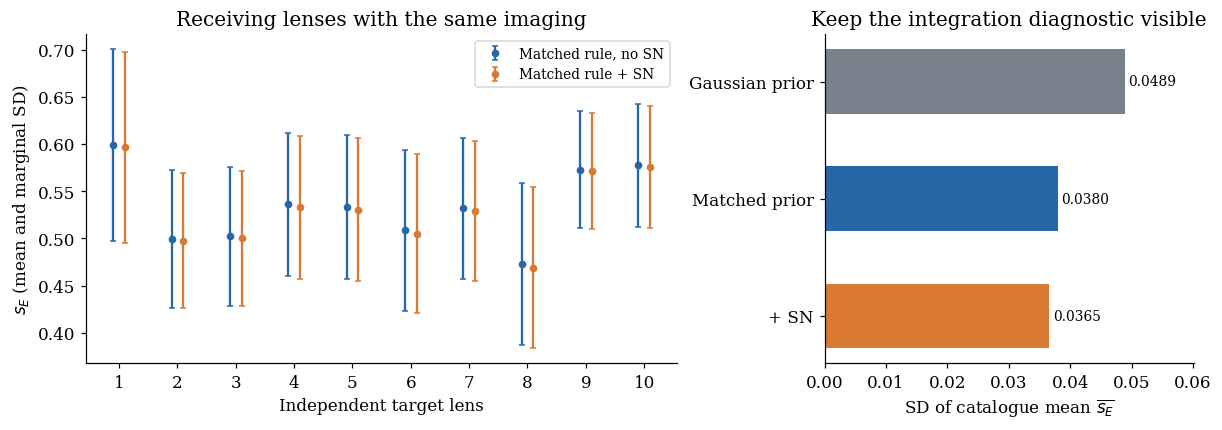

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True,
                         gridspec_kw={"width_ratios": [1.6, 1]})
index = np.arange(1, len(after.mean) + 1)
for summary, offset, color, label in (
    (matched_before, -0.10, BLUE, "Matched rule, no SN"),
    (after, 0.10, ORANGE, "Matched rule + SN"),
):
    axes[0].errorbar(index + offset, summary.mean, yerr=summary.standard_deviation,
                     fmt="o", ms=4, capsize=2, color=color, label=label)
axes[0].set(xlabel="Independent target lens", ylabel=r"$s_E$ (mean and marginal SD)",
            xticks=index, title="Receiving lenses with the same imaging")
axes[0].legend(fontsize=9)
widths = [gaussian_before.catalogue_mean_sd, matched_before.catalogue_mean_sd,
          after.catalogue_mean_sd]
axes[1].barh([2, 1, 0], widths, color=[GRAY, BLUE, ORANGE], height=0.55)
axes[1].set(yticks=[2, 1, 0], yticklabels=["Gaussian prior", "Matched prior", "+ SN"],
            xlabel=r"SD of catalogue mean $\overline{s_E}$",
            title="Keep the integration diagnostic visible", xlim=(0, max(widths) * 1.23))
for y, width in zip([2, 1, 0], widths):
    axes[1].text(width + 0.0006, y, f"{width:.4f}", va="center", fontsize=9)
plt.show()

## 7. See the shared uncertainty in the covariance

At fixed common coordinates, target mass states are independent. After integrating the common population and contrast, their inferred $s_E$ values are correlated:

$$C_{ij}=\operatorname{Cov}_{\eta,\delta}(m_i,m_j)
        +\mathbf{1}_{i=j}\,\mathbb{E}_{\eta,\delta}[v_i],
\qquad \operatorname{Var}(\overline{s_E})=\frac{\sum_{ij}C_{ij}}{J^2}.$$

Each heatmap cell is the covariance between the row lens and column lens. The diagonal includes individual mass-state uncertainty; the off-diagonal entries come from shared parameters. Both panels use the same color scale. Omitting the off-diagonal covariance understates the catalogue-mean uncertainty here.

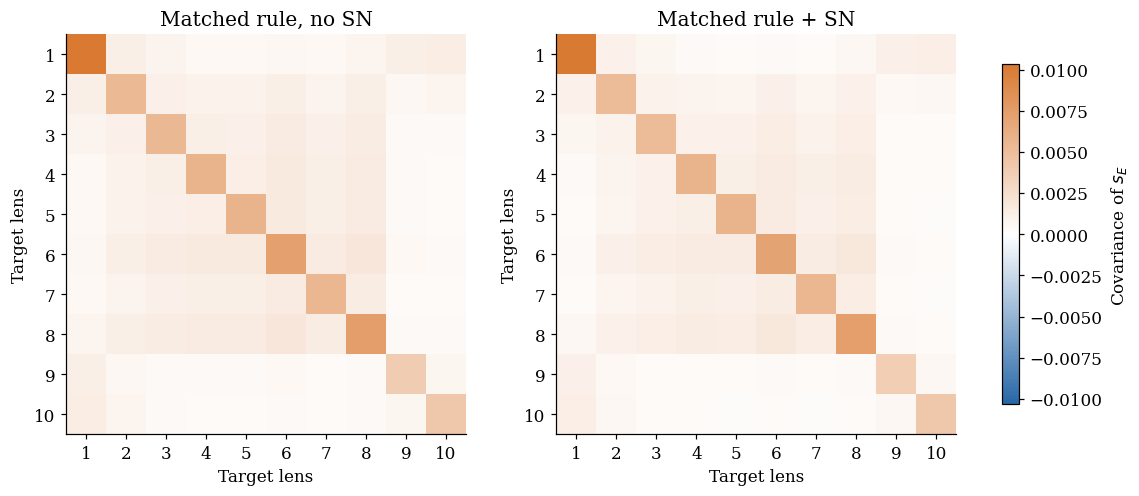

Catalogue-mean SD with full covariance: 0.036545
Using only its diagonal:                0.024453
Shared-parameter contribution in quadrature: 0.029519


In [9]:
covariances = [matched_before.covariance, after.covariance]
limit = max(np.abs(c).max() for c in covariances)
cmap = LinearSegmentedColormap.from_list("blue_white_orange", [BLUE, "#FFFFFF", ORANGE])
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.4), constrained_layout=True)
for ax, covariance, title in zip(axes, covariances, ["Matched rule, no SN", "Matched rule + SN"]):
    mesh = ax.imshow(covariance, cmap=cmap,
                     norm=TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit))
    ax.set(title=title, xlabel="Target lens", ylabel="Target lens",
           xticks=np.arange(len(index)), yticks=np.arange(len(index)),
           xticklabels=index, yticklabels=index)
fig.colorbar(mesh, ax=axes, label=r"Covariance of $s_E$", shrink=0.85)
plt.show()

independent_only_sd = np.sqrt(np.trace(after.covariance)) / len(after.mean)
shared_mean_sd = np.sqrt(max(after.shared_covariance.sum(), 0)) / len(after.mean)
print(f"Catalogue-mean SD with full covariance: {after.catalogue_mean_sd:.6f}")
print(f"Using only its diagonal:                {independent_only_sd:.6f}")
print(f"Shared-parameter contribution in quadrature: {shared_mean_sd:.6f}")

## 8. Optional: widen the source–target contrast

The source posterior stays fixed while we multiply the contrast's coordinate SD by **0, 1, or 2**. Scale 0 imposes identical source and receiving population coordinates; scale 1 is the supplied assumption. Both no-SN and SN readouts use the same finite source rule, seed and target observations at each scale.

This scan tests sensitivity to population portability. The common contrast can leave a shared uncertainty floor as SN information increases. The difference across scales is a sensitivity calculation, not a separately measured contrast variance or a converged survey forecast.

In [10]:
contrast_scan = []
if RUN_CONTRAST_SCAN:
    for scale in (0, 1, 2):
        covariance = scale**2 * contrast_covariance
        before_nodes, before_weights = receiving_nodes(
            eta, source_prior_probability, covariance, n=N_RECEIVING, seed=SEED)
        after_nodes, after_weights = receiving_nodes(
            eta, source_posterior_probability, covariance, n=N_RECEIVING, seed=SEED)
        prior_summary, _ = target_readout(target_population, targets, before_nodes, before_weights)
        sn_summary, _ = target_readout(target_population, targets, after_nodes, after_weights)
        contrast_scan.append((scale, prior_summary, sn_summary))
    print(f"{'Contrast SD scale':>17s} {'No-SN SD':>10s} {'SN SD':>10s} {'SN ratio':>10s} {'Shared SN SD':>13s}")
    for scale, prior_summary, sn_summary in contrast_scan:
        shared_sd = np.sqrt(max(sn_summary.shared_covariance.sum(), 0)) / len(sn_summary.mean)
        print(f"{scale:17.1f} {prior_summary.catalogue_mean_sd:10.6f} "
              f"{sn_summary.catalogue_mean_sd:10.6f} "
              f"{sn_summary.catalogue_mean_sd / prior_summary.catalogue_mean_sd:10.4f} "
              f"{shared_sd:13.6f}")
else:
    print("Contrast scan skipped; set RUN_CONTRAST_SCAN=True to run it.")

Contrast SD scale   No-SN SD      SN SD   SN ratio  Shared SN SD
              0.0   0.031436   0.030615     0.9739      0.021371
              1.0   0.037952   0.036545     0.9629      0.029519
              2.0   0.049083   0.049741     1.0134      0.045037


The solid curves below retain every covariance element. The dashed orange curve isolates the shared-parameter contribution to the SN catalogue-mean variance; it includes both source-population uncertainty and the independent common contrast. It should not be relabelled as a pure $\delta$ contribution.

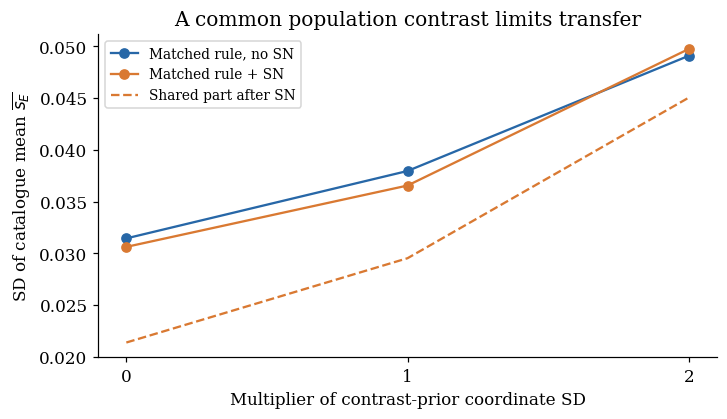

SN catalogue SD changes from 0.030615 at zero contrast to 0.036545 at the supplied contrast and 0.049741 at twice its SD.


In [11]:
if contrast_scan:
    scales = np.array([row[0] for row in contrast_scan])
    no_sn_sd = np.array([row[1].catalogue_mean_sd for row in contrast_scan])
    sn_sd = np.array([row[2].catalogue_mean_sd for row in contrast_scan])
    shared_sd = np.array([np.sqrt(max(row[2].shared_covariance.sum(), 0))
                          / len(row[2].mean) for row in contrast_scan])
    fig, ax = plt.subplots(figsize=(6.5, 3.7), constrained_layout=True)
    ax.plot(scales, no_sn_sd, "o-", color=BLUE, label="Matched rule, no SN")
    ax.plot(scales, sn_sd, "o-", color=ORANGE, label="Matched rule + SN")
    ax.plot(scales, shared_sd, "--", color=ORANGE, label="Shared part after SN")
    ax.set(xlabel="Multiplier of contrast-prior coordinate SD",
           ylabel=r"SD of catalogue mean $\overline{s_E}$", xticks=scales,
           title="A common population contrast limits transfer")
    ax.legend(fontsize=9)
    plt.show()
    print(f"SN catalogue SD changes from {sn_sd[0]:.6f} at zero contrast "
          f"to {sn_sd[1]:.6f} at the supplied contrast and {sn_sd[2]:.6f} at twice its SD.")

## 9. Exercise: a null source likelihood

If the SN likelihood is constant over every joint node, should adding it change the receiving distribution? Replace the source likelihood by zeros in log space, retaining the saved joint prior/proposal weights. The next cell supplies the answer scaffold and checks the full covariance.

A null update must leave the **matched** comparison unchanged. It does not force the coarse finite prior to agree with the Gaussian-prior reference. This is the distinction between an SN update and an integration discrepancy.

In [12]:
null_log_likelihood = np.zeros(len(eta))
null_log_weight = log_prior_weight + null_log_likelihood
null_probability = np.exp(null_log_weight - logsumexp(null_log_weight))
null_nodes, null_weights = receiving_nodes(
    eta, null_probability, contrast_covariance, n=N_RECEIVING, seed=SEED)
null_summary, _ = target_readout(target_population, targets, null_nodes, null_weights)
assert np.allclose(null_summary.mean, matched_before.mean)
assert np.allclose(null_summary.covariance, matched_before.covariance)
print(f"Null likelihood / matched-prior width ratio: "
      f"{null_summary.catalogue_mean_sd / matched_before.catalogue_mean_sd:.6f}")
print(f"No-SN finite-rule minus Gaussian-reference SD: "
      f"{matched_before.catalogue_mean_sd - gaussian_before.catalogue_mean_sd:+.6f}")

Null likelihood / matched-prior width ratio: 1.000000
No-SN finite-rule minus Gaussian-reference SD: -0.010925


## What this calculation establishes

We recomputed the selected-source likelihood, shared-nuisance posterior and target covariance from simulation inputs. The matched comparison measures the SN update **conditional on this physical family, supplied selection/response and finite integration rule**. The contrast scan makes the assumed source–target relation visible.

Two sources, a fixed $q=5$ family without redistribution and a low-effective-count source rule do not establish Roman survey precision, bias or coverage. A useful next calculation refines the source integration independently, repeats receiving seeds/counts, and varies justified radial and contrast priors before quoting a population gain.

See [input assumptions](../data/README.rst), [scientific model](../docs/science.rst), [API usage](../docs/usage.rst) and the [script form of the calculation](../examples/roman_transfer.py).